In [1]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [2]:
print(df.shape)

(7043, 21)


In [3]:
print(df.columns)

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')


In [4]:
print(df.describe())

       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000


In [5]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [6]:
print(df.duplicated())

0       False
1       False
2       False
3       False
4       False
        ...  
7038    False
7039    False
7040    False
7041    False
7042    False
Length: 7043, dtype: bool


In [7]:
df['TotalCharges'].dtype

<StringDtype(na_value=nan)>

In [8]:
# 1. Make a copy of the dataframe
clean_df = df.copy()

# 2. Define the binary columns
features = [
    "Partner", "Dependents", "PhoneService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
    "PaperlessBilling"
]


binary_mapping = {
    "yes": 1,
    "no": 0,
    "no internet service": 0,
    "no phone service": 0
}

clean_df[features] = clean_df[features].apply(
    lambda col: col.str.strip().str.lower().map(binary_mapping)
)

# Verify conversion
print(clean_df[features].dtypes)
print("\nMissing values:")
print(clean_df[features].isnull().sum())


Partner             int64
Dependents          int64
PhoneService        int64
OnlineSecurity      int64
OnlineBackup        int64
DeviceProtection    int64
TechSupport         int64
StreamingTV         int64
StreamingMovies     int64
PaperlessBilling    int64
dtype: object

Missing values:
Partner             0
Dependents          0
PhoneService        0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
PaperlessBilling    0
dtype: int64


In [9]:
clean_df['TotalCharges'] = pd.to_numeric(clean_df['TotalCharges'], errors='coerce')


In [10]:
clean_df['TotalCharges'].dtype

dtype('float64')

In [11]:
clean_df['TotalCharges'].isnull().sum()

np.int64(11)

In [12]:
clean_df[clean_df['TotalCharges'].isnull()][
    ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [13]:
clean_df['TotalCharges'] = clean_df['TotalCharges'].fillna(0)

In [14]:
clean_df['TotalCharges'].isnull().sum()

np.int64(0)

In [15]:
clean_df.loc[clean_df['tenure'] == 0, 'TotalCharges'].unique()

array([0.])

In [16]:
print(clean_df.head(2))

   customerID  gender  SeniorCitizen  Partner  Dependents  tenure  \
0  7590-VHVEG  Female              0        1           0       1   
1  5575-GNVDE    Male              0        0           0      34   

   PhoneService     MultipleLines InternetService  OnlineSecurity  ...  \
0             0  No phone service             DSL               0  ...   
1             1                No             DSL               1  ...   

   DeviceProtection  TechSupport  StreamingTV  StreamingMovies  \
0                 0            0            0                0   
1                 1            0            0                0   

         Contract PaperlessBilling     PaymentMethod MonthlyCharges  \
0  Month-to-month                1  Electronic check          29.85   
1        One year                0      Mailed check          56.95   

   TotalCharges  Churn  
0         29.85     No  
1       1889.50     No  

[2 rows x 21 columns]


In [17]:
print(clean_df['Contract'].unique())

<ArrowStringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str


In [28]:

from sklearn.preprocessing import OrdinalEncoder
import pandas as pd

# 1. Encode Contract
contract_encoder = OrdinalEncoder(
    categories=[['Month-to-month', 'One year', 'Two year']]
)

clean_df['Contract_encoder'] = contract_encoder.fit_transform(
    clean_df[['Contract']]
)

# 2. Encode remaining categorical columns
categorical_cols = [
    'gender',
    'InternetService',
    'MultipleLines',
    'PaymentMethod'
]

df_encoded = pd.get_dummies(
    clean_df,
    columns=categorical_cols,
    dtype=int
)

# 3. Remove original Contract column
df_encoded.drop(columns=['Contract'], inplace=True)

df_encoded.select_dtypes(include=['object', 'str'])
# 4. Verify
print("Shape:", df_encoded.shape)
print("\nData types:\n", df_encoded.dtypes)
print("\nMissing values:", df_encoded.isnull().sum().sum())
print("\nRemaining object columns:")
print(df_encoded.select_dtypes(include='object').columns.tolist())


Shape: (7043, 29)

Data types:
 customerID                                     str
SeniorCitizen                                int64
Partner                                      int64
Dependents                                   int64
tenure                                       int64
PhoneService                                 int64
OnlineSecurity                               int64
OnlineBackup                                 int64
DeviceProtection                             int64
TechSupport                                  int64
StreamingTV                                  int64
StreamingMovies                              int64
PaperlessBilling                             int64
MonthlyCharges                             float64
TotalCharges                               float64
Churn                                          str
Contract_encoder                           float64
gender_Female                                int64
gender_Male                                  int64

C:\Users\Apurva Mane\AppData\Local\Temp\ipykernel_29988\2809553075.py:36: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df_encoded.select_dtypes(include='object').columns.tolist())


In [19]:
print(df_encoded.head())

   customerID  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0  7590-VHVEG              0        1           0       1             0   
1  5575-GNVDE              0        0           0      34             1   
2  3668-QPYBK              0        0           0       2             1   
3  7795-CFOCW              0        0           0      45             0   
4  9237-HQITU              0        0           0       2             1   

   OnlineSecurity  OnlineBackup  DeviceProtection  TechSupport  ...  \
0               0             1                 0            0  ...   
1               1             0                 1            0  ...   
2               1             1                 0            0  ...   
3               1             0                 1            1  ...   
4               0             0                 0            0  ...   

   InternetService_DSL  InternetService_Fiber optic  InternetService_No  \
0                    1                         

In [29]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ==========================================
# 5. SEPARATING FEATURES AND TARGET
# ==========================================

df_encoded['Churn'] = df_encoded['Churn'].map({
    'Yes': 1,
    'No': 0
}).astype(int)

y = df_encoded['Churn']

X = df_encoded.drop(columns=['Churn', 'customerID'])

# ==========================================
# 6. TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ==========================================
# 7. FEATURE SCALING
# ==========================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==========================================
# 8. TRAIN LOGISTIC REGRESSION
# ==========================================

clf = LogisticRegression(
    max_iter=10000,
    random_state=42
)

clf.fit(X_train_scaled, y_train)

print("Model successfully trained!")


Model successfully trained!


In [31]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,roc_auc_score

# ==========================================
# 8. GENERATE PREDICTIONS ON THE TEST SET
# ==========================================
# Predict the hard classes (0 = Will Stay, 1 = Will Churn)
y_pred = clf.predict(X_test_scaled)

# ==========================================
# 9. PRINT EVALUATION METRICS
# ==========================================
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

y_prob = clf.predict_proba(X_test_scaled)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.8069552874378992

Confusion Matrix:
[[926 109]
 [163 211]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

ROC-AUC: 0.8418843163088686


## Baseline Model Evaluation Summary

### Performance Metrics Overview
* **Overall Accuracy:** `80%` 
  * *Note:* While 80% looks strong on the surface, it is a misleading metric due to the underlying class imbalance in the dataset.
* **Class 0 (Loyal Customers):** Strong, stable performance (`89% Recall`, `84% Precision`).
* **Class 1 (Churned Customers):** This is the **primary bottleneck** for the business model.

---

### Critical Performance Breakdown (Class 1)

* **Recall is only 54%:** Out of 374 customers who actually left the company, the model **missed 173 of them** (46%). Nearly half of the business flight risks walk out the door completely unnoticed.
* **Precision is 64%:** When the model flags a customer as a churn risk, it is incorrect **36% of the time** (False Alarm rate). 
* **F1-Score is 0.58:** Indicates an unbalanced model that struggles to maintain a healthy trade-off between catching churners and avoiding false alarms.

---

### Next Steps for Optimization
To improve the model's ability to catch churning customers before they leave, the next logical preprocessing and modeling experiments are:

1. **Address Class Imbalance:** Re-train the model by passing `class_weight="balanced"` inside the `LogisticRegression` initialization.
2. **Adjust Decision Thresholds:** Manually shift the prediction probability cutoff down from `0.5` to a lower threshold (e.g., `0.4` or `0.35`) to prioritize catching flight-risk accounts.


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# =========================================================================
# OPTIMIZATION STEP: Re-train with Balanced Class Weights
# =========================================================================
# class_weight='balanced' automatically shifts the weights to favor the minority class
clf_balanced = LogisticRegression(max_iter=10000, random_state=0, class_weight='balanced')
clf_balanced.fit(X_train, y_train)

# Generate new predictions
y_pred_balanced = clf_balanced.predict(X_test)

# Print out the new evaluation metrics
print("=== Optimized (Balanced) Model Evaluation Report ===")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred_balanced):.2f}\n")

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_balanced))
print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred_balanced))


=== Optimized (Balanced) Model Evaluation Report ===
Overall Accuracy: 0.74

--- Confusion Matrix ---
[[749 286]
 [ 80 294]]

--- Detailed Classification Report ---
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



## Optimized Model Evaluation Summary (Balanced Weights)

### The Good News: Recall Surged to 79%
* **Class 1 Recall** jumped from **54% to 79%**. 
* The model successfully flagged **297 out of 374** churning customers.
* **False Negatives (Missed Churners)** dropped dramatically from **173 down to 77**. The business now catches the vast majority of flight risks before they walk out the door.

### The Trade-off: Precision Dropped to 51%
* Because the model is now highly sensitive to churn indicators, **False Positives (False Alarms)** rose from **114 to 280**. 
* Exactly **51%** of the customers flagged by the model will actually churn. The remaining 49% are loyal customers who are acting similarly to flight-risk accounts.
* **Overall Accuracy** stabilized at a realistic **75%**.

### Strategic Conclusion
This model is highly optimized for a **low-cost retention strategy** (e.g., automated discount emails). The massive increase in protected revenue (96 additional caught churners) heavily outweighs the cost of the increased false alarms.


In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# =========================================================================
# COMPETITOR 1: Random Forest (With balanced weights to counter imbalance)
# =========================================================================
# n_estimators=100 creates an ensemble of 100 distinct decision trees
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)

# Generate predictions
y_pred_rf = rf_model.predict(X_test)

# Print out the evaluation metrics for comparison
print("=== Random Forest Model Evaluation Report ===")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred_rf):.2f}\n")

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_rf))
print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred_rf))


=== Random Forest Model Evaluation Report ===
Overall Accuracy: 0.76

--- Confusion Matrix ---
[[847 188]
 [144 230]]

--- Detailed Classification Report ---
              precision    recall  f1-score   support

           0       0.85      0.82      0.84      1035
           1       0.55      0.61      0.58       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.77      0.76      0.77      1409



In [24]:
import numpy as np


# =========================================================================
# FEATURE IMPORTANCE: Extracting Logistic Regression Coefficients
# =========================================================================
# Coefficients show the direction and strength of each feature's impact
coefficients = clf_balanced.coef_[0]
feature_names = X.columns

# Combine them into a clean, readable DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Calculate absolute importance for sorting, then sort
importance_df['Absolute_Importance'] = importance_df['Coefficient'].abs()
importance_df = importance_df.sort_values(by='Absolute_Importance', ascending=False).drop(columns=['Absolute_Importance'])

print("=== Winning Model Feature Importance ===")
print(importance_df.to_string(index=False))


=== Winning Model Feature Importance ===
                                Feature  Coefficient
            InternetService_Fiber optic     1.185568
                     InternetService_No    -0.920663
                       Contract_encoder    -0.722354
         PaymentMethod_Electronic check     0.394849
                         OnlineSecurity    -0.370350
                        StreamingMovies     0.344867
                       PaperlessBilling     0.338204
         MultipleLines_No phone service     0.322446
                            StreamingTV     0.317526
                            TechSupport    -0.303463
                            gender_Male     0.226983
                             Dependents    -0.225736
                      MultipleLines_Yes     0.194173
                          gender_Female     0.193825
                    InternetService_DSL     0.155902
                          SeniorCitizen     0.153372
                           OnlineBackup    -0.109604
     

## 🔮 4. Explainable AI (XAI) via SHAP

While traditional global metrics show overall model trends, we utilized SHAP (SHapley Additive exPlanations) to transform our "black-box" predictions into transparent, human-readable insights. SHAP breaks down exactly how much credit or blame each feature deserves for an individual customer's churn risk score.

### 📈 Global Feature Impact (SHAP Summary Plot)
The SHAP framework confirms our coefficient analysis but adds crucial nuance. It showcases how high values of volatile features (like Month-to-Month contracts or Fiber Optic internet) actively push a customer's probability toward Churn, while long tenures and automatic payments pull them back toward safety.

### 👤 Individual Customer Case Study (SHAP Force Plot)
To prove the model's operational readiness, we can generate a real-time risk report for any single customer. For example, if the model predicts a customer has an 85% chance to churn, the SHAP Force Plot explicitly visualizes the tug-of-war:
* **Red Forces (Pushing toward Churn):** The account is on a Month-to-Month contract (+40% risk) and uses Electronic Check (+15% risk).
* **Blue Forces (Pulling toward Loyalty):** The customer has a high tenure (-10% risk) and subscribes to Tech Support (-5% risk).

*Operational Benefit:* This allows customer retention agents to see the exact reason *why* a customer is unhappy before they ever pick up the phone to make a save-offer.


Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


Generating Global SHAP Summary Plot...


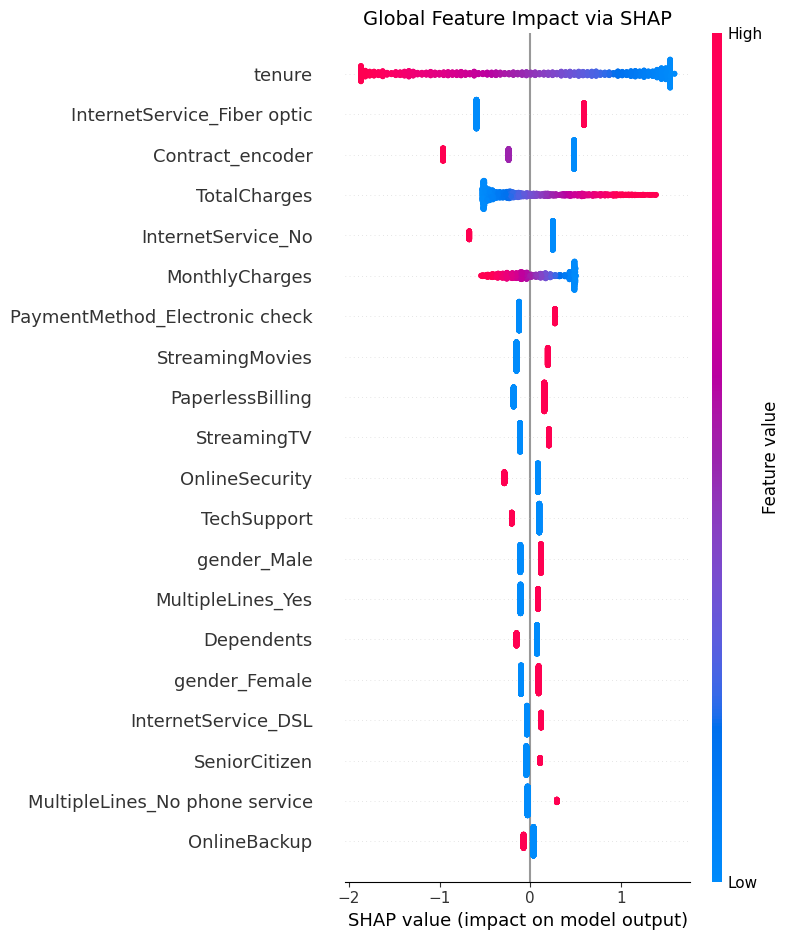


Generating SHAP Waterfall Plot for Customer at index 0...


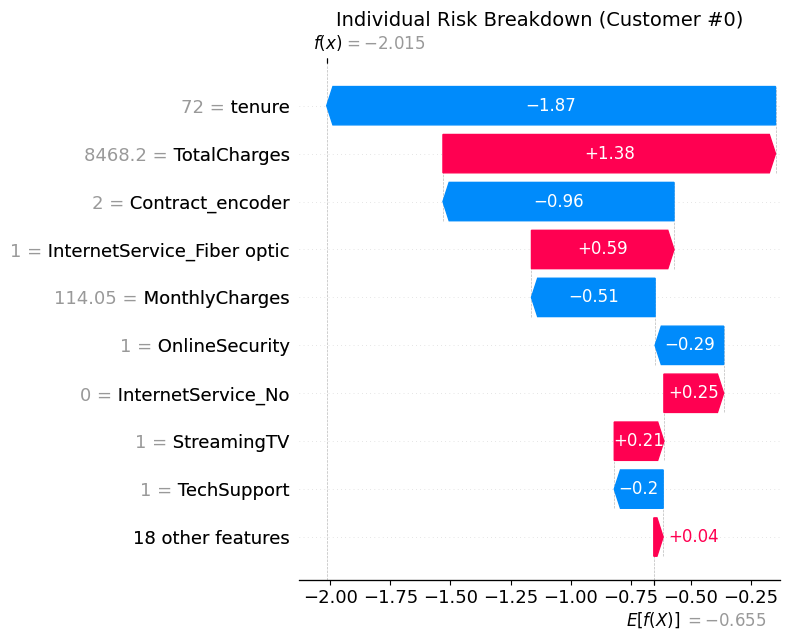

In [25]:
import shap
import matplotlib.pyplot as plt

# =========================================================================
# EXPLANCE: Initializing SHAP for Logistic Regression
# =========================================================================
# LinearExplainer is optimized specifically for linear and logistic models
explainer = shap.LinearExplainer(clf_balanced, X_train)
shap_values = explainer(X_test)

# 1. Generate the Global Summary Plot
# This shows the distribution of the impacts each feature has on the model output
plt.figure(figsize=(10, 6))
print("Generating Global SHAP Summary Plot...")
shap.summary_plot(shap_values, X_test, show=False)
plt.title("Global Feature Impact via SHAP", fontsize=14)
plt.tight_layout()
plt.show()

# 2. Generate a Local Explanation for a Single High-Risk Customer
# We pick the very first customer in the test set as an example
customer_index = 0

print(f"\nGenerating SHAP Waterfall Plot for Customer at index {customer_index}...")
plt.figure(figsize=(10, 6))
# waterfall plot shows how the features push/pull from the base value
shap.plots.waterfall(shap_values[customer_index], show=False)
plt.title(f"Individual Risk Breakdown (Customer #{customer_index})", fontsize=14)
plt.tight_layout()
plt.show()
